# Reporte de Evidencias: Econometría I
Del 4 de febrero al 11 de febrero de 2026

## Índice
1. [Objetivo del análisis](#objetivo)
2. [Fundamentos de Python para Econometría](#fundamentos)
3. [Especificación del Modelo de Regresión Múltiple](#especificacion)
4. [Implementación de Código e Interpretación de Resultados](#implementacion)
5. [Aprendizajes y Aplicaciones Prácticas](#aprendizajes)



#Objetivo del análisis <a name="objetivo"></a>


En este periodo, tuvimos como objetivo desarrollar habilidades técnicas para estimar y validar un Modelo de Regresión Lineal Múltiple utilizando Python y comprender cómo una variable dependiente puede  ($y$) ser explicada por múltiples variables independientes ($x_1, x_2$), evaluando la significancia estadística de los parámetros y la capacidad predictiva del modelo mediante métricas como el $R^2$

#Fundamentos de Python para Econometría <a name="fundamentos"></a>

Antes de empezar con el Modelo de Regresión Lineal Múltiple, repasamos algunas estructuras básicas para la manipulación de datos:

In [1]:
nombre="Alejandro"
edad=21
print("Nombre:",nombre)
print("Edad:",edad)


Nombre: Alejandro
Edad: 21


Condicionales

In [2]:
if edad>=18:
    print("Es mayor de edad")
else:
    print("Es menor de edad")

Es mayor de edad


Bucles

In [3]:
for i in range(6):
    print("Hola",i)

Hola 0
Hola 1
Hola 2
Hola 3
Hola 4
Hola 5


Funciones

In [4]:
def saludar(nombre):
    print("Hola",nombre)

saludar("Maria")

Hola Maria


In [5]:
frutas=["manzana","platano","pera"]
print(frutas[1])
print(frutas[0])

platano
manzana


#Especificación del Modelo de Regresión Múltiple <a name="especificacion"></a>

Con este modelo buscamos estimar una relación donde una variable dependiente ($y$) es explicada por dos variables independientes ($x_1$ y $x_2$).

Nuestro modelo de Regresión Lineal Múltiple se ve de esta forma:\
$$y = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \epsilon$$
Donde:\
$\beta_0$: Es el intercepto.\
$\beta_1, \beta_2$: Son los coeficientes de las variables explicativas, nos dicen que tanto aumenta ($y$) por cada unidad de ($x_1$ y $x_2$) .\
$\epsilon$: Es el error aleatorio (el "ruido" que no podemos explicar).

#Implementación de Código e Interpretación de Resultados <a name="implementacion"></a>

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
np.random.seed(42)

In [7]:
#Crear una serie de datos sencillos
#numero de observaciones
n=80
#Variables explicativas simples
x1=np.random.normal(10,2,n)
x2=np.random.normal(5,1.5,n)
#Error aleatorio
eps=np.random.normal(0,3,n)
#Variable dependiente
y=5+2*x1+3*x2+eps
df=pd.DataFrame({"y":y,"x1":x1,"x2":x2})
df.head()

,y,x1,x2
0,38.074288,10.993428,4.670492
1,43.415203,9.723471,5.535669
2,52.717064,11.295377,7.216841
3,41.297856,13.046060,4.222595
4,38.315294,9.531693,3.787260


Al utilizar el método de Mínimos Cuadrados Ordinarios (MCO), buscamos los estimadores que minimicen la suma de los errores al cuadrado:

In [8]:
#Ajustamos el modelo con MCO
X=df[["x1","x2"]]
X=sm.add_constant(X)#Agrega intercepto
model=sm.OLS(df["y"],X).fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.730
Model:                            OLS   Adj. R-squared:                  0.723
Method:                 Least Squares   F-statistic:                     104.1
Date:                Mon, 16 Feb 2026   Prob (F-statistic):           1.29e-22
Time:                        20:59:51   Log-Likelihood:                -201.54
No. Observations:                  80   AIC:                             409.1
Df Residuals:                      77   BIC:                             416.2
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          9.2197      2.191      4.207      0.000       4.856      13.583
x1             1.7869      0.180      9.929      0.000       1.429       2.145
x2             2.6473      0.250     10.573      0.000       2.149       3.146
==============================================================================
Omnibus:                        6.929   Durbin-Watson:                   1.941
Prob(Omnibus):                  0.031   Jarque-Bera (JB):                6.278
Skew:                           0.594   Prob(JB):                       0.0433
Kurtosis:                       3.689   Cond. No.                         71.6
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Con las variables $x_1$ y $x_2$ decimos que por cada unidad que aumenta $x_1$, $y$ aumenta 1.79 unidades, manteniendo $x_2$ constante y por cada unidad que aumenta $x_2$, $y$ aumenta 2.65 unidades, manteniendo $x_1$ constante. Y si $x_1$ y $x_2$ fueran cero, el valor esperado de $y$ sería 9.22.
Otra cosa que podemos ver es el p-value , los cuales son menores a 0.05, lo que indica que las variables son estadísticamente significativas , es decir si explican a nuestra variable dependiente , además nuestra $R^2$ de 0.730 nos dice que el modelo explica el 73% de la variabilidad de $y$.

Algo importante que observamos es la prueba de Durbin Watson , la cual nos dice si nuestros errores tienen autocorrelación, teniendo un coeficiente de 1.941 podemos decir que no tenemos problemas de autocorrelación pues nuestro coeficiente està muy cerca del 2. Tambièn vemos el test de jarque-Bera, el cual nos mide la normalidad de los residuos basàndose en la simetrìa y la kurtosis

In [9]:
#Predicciones
y_hat=model.fittedvalues
y_mean=df["y"].mean()
df["y_hat"]=y_hat
df.head()

,y,x1,x2,y_hat
0,38.074288,10.993428,4.670492,41.228029
1,43.415203,9.723471,5.535669,41.249158
2,52.717064,11.295377,7.216841,48.508592
3,41.297856,13.046060,4.222595,43.710129
4,38.315294,9.531693,3.787260,36.277864


En esta tabla vemos que el valor real de (y) es 38.07 y la predicción del modelo (y_hat) es 41.22, la difernecia entre esos dos números es lo que conocemos como el error y nuestro objetivo en regresión es que, en promedio, esas diferencias sean lo más pequeñas posible.

In [10]:
y_obs=df["y"]

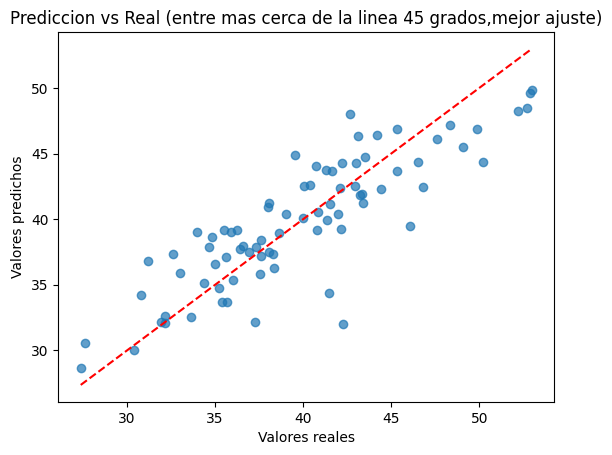

In [11]:
plt.scatter(y_obs,y_hat, alpha=0.7)
plt.xlabel("Valores reales")
plt.ylabel("Valores predichos")
plt.title("Prediccion vs Real (entre mas cerca de la linea 45 grados,mejor ajuste)")
plt.plot([y_obs.min(),y_obs.max()],[y_obs.min(),y_obs.max()],'r--')

En esta gráfica vemos que si tenemos una buena relación lineal. La línea roja es nuestra referencia de predicción perfecta, mientras que los puntos azules muestran qué tan cerca estuvimos de esa perfección en cada dato. Como la nube de puntos se alinea estrechamente con la diagonal, visualizamos que el modelo tiene un buen poder explicativo. Por otro lado un aspecto fundamental que garantiza la eficiencia de nuestros estimadores MCO es el cumplimiento del supuesto de Homocedasticidad. Este implica que la varianza de los errores debe ser constante a lo largo de todas las observaciones. En nuestro modelo, al observar la nube de puntos en la gráfica de 'Predicción vs Real', no detectamos un patrón de 'abanico' o embudo, lo que sugiere intuitivamente que no sufrimos de heterocedasticidad. Si la varianza no fuera constante, los errores estándar estarían sesgados, lo que invalidaría nuestras pruebas de significancia $t$ y los intervalos de confianza

In [12]:
y_obs=df["y"]
#Variacion total
SST=np.sum((y_obs-y_mean)**2)
#Variacion explicada
SSR=np.sum((y_hat-y_mean)**2)
#Variacion no explicada(error)
SSE=np.sum((y_obs-y_hat)**2)
SST,SSR,SSE

(np.float64(2674.8661909870266),
 np.float64(1952.4608504770372),
 np.float64(722.4053405099884))

En esta parte, primero calculamos la suma de cuadrados totales , es decir la variabilidad total de nuestraa variable dependiente $y$, con esto medimos qué tanto varían los datos observados respecto a su propia media ($\bar{y}$). Luego calculamos la suma de cuadrados de la regresión, la cual es la a variación explicada por el modelo, aquì medimos qué tan lejos están nuestras predicciones ($\hat{y}$) de la media simple, por último calculamos la suma de cuadrados del error para medir la distancia (al cuadrado) entre el valor real y lo que predijo nuestro modelo. Teniendo estos tres resultados podemos calcular $R^2$ (Coeficiente de Determinación) de forma manual :

In [13]:
#Verificamos la relacion
print("SST =",SST)
print("SSR +SSE =",SSR+SSE)
print("Diferencia numerica=", SST-(SSR+SSE))
#Calculo manual de R2
R2_manual=SSR/SST
R2_model=model.rsquared
print("R2(manual):",R2_manual)
print("R2(modelo statsmodels):",R2_model)

SST = 2674.8661909870266
SSR +SSE = 2674.8661909870257
Diferencia numerica= 9.094947017729282e-13
R2(manual): 0.7299284192442458
R2(modelo statsmodels): 0.7299284192442461


Aqui hacemos el cálculo de forma manual , en la primera línea sumamos a variación que tu modelo explica ($SSR$) y la que no explica ($SSE$), lo que es igual a la variación total original ($SST$), después tenemos otro resultado que es la diferencia numérica, el cual es un número muy pequeño (casi cero), lo que confirma que toda la variabilidad de nuestros datos está perfectamente contada, es decir que, no perdimos información en el camino. Y ya hasta el final tnemeos el Cálculo Manual de la $R^2$ , el cual fue obtenido dividiendo $SSR / SST$.

#Aprendizajes y Aplicaciones Prácticas <a name="aprendizajes"></a>

Con esta primera actividad aprendimos a utilizar herramientas como statsmodels para realizar Regresiones Múltiples por Mínimos Cuadrados Ordinarios (MCO) y  matplotlib para crear gráficas de dispersión que contrastan los valores reales contra las predicciones del modelo. Además reforzamos nuestros conocimientos obtenidos en estadística 2 , al interpretar nuestros resultados .


Este mismo esquema de regresión múltiple nos permite estimar el valor de un activo (como una acción o una propiedad) basándonos en variables macroeconómicas, por ejemplo si tomamos a ($y$) como el rendimiento mensual de Apple, ($x_1$) como la tasa de interés de los bonos del Tesoro y ($x_2$) como el Índice de Precios al Consumidor (Inflación), con los coeficientes $\beta$ podemos ver el impacto marginal de cada variable. Por ejemplo, un aumento en las tasas de interés ($x_1$) suele tener un impacto negativo en las acciones de crecimiento.
También podriamos resolver problemas de optimización, por ejemplo , en una empresa podemos usar este modelo para medir el Retorno de Inversión, si porponemos a $y$ como las ventas mensuales, $x_1$ la inversión en publicidad digital y $x_2$ el número de vendedores, los coeficientes nos dirían exactamente en qué área es más rentable invertir.